# 1 · Read, don't write: decisions and calibration from a small LLM

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nipunbatra/system-one/blob/main/notebooks/01_read_dont_write.ipynb)

Companion to the lecture **System 1 models: deciding without writing**.

We take a small open LLM (Qwen2.5-0.5B-Instruct, 494 M parameters) and

1. watch it generate an answer one token at a time,
2. read the answer's probabilities from a **single forward pass** instead,
3. measure whether those probabilities can be trusted (reliability diagram, ECE),
4. fix them with one number (temperature scaling),
5. turn them into decisions with thresholds.

Runs on a free Colab runtime. A T4 GPU (Runtime → Change runtime type) makes step 3 take about a minute; on CPU it takes about ten.

In [1]:
%pip install -q transformers datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json, time, numpy as np, torch
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
name = "Qwen/Qwen2.5-0.5B-Instruct"          # 494 M parameters, a decoder-only transformer
tok = AutoTokenizer.from_pretrained(name)
tok.padding_side = "left"                     # so the last position is always the real last token
model = AutoModelForCausalLM.from_pretrained(name, dtype=torch.float32).to(device).eval()
print(device, f"{sum(p.numel() for p in model.parameters())/1e6:.0f} M parameters,",
      model.config.num_hidden_layers, "layers, vocabulary", model.config.vocab_size)

mps 494 M parameters, 24 layers, vocabulary 151936


## 1. Text becomes tokens

Our running example is one support email. The model never sees letters or words, only token ids.

In [3]:
email = "I was charged twice this month, please fix it."
ids = tok(email)["input_ids"]
tokens = [tok.decode([i]) for i in ids]
print(len(ids), "tokens")
for i, t in zip(ids, tokens):
    print(f"{i:>7}  {t!r}")

11 tokens
     40  'I'
    572  ' was'
  11430  ' charged'
  10917  ' twice'
    419  ' this'
   2254  ' month'
     11  ','
   4486  ' please'
   5046  ' fix'
    432  ' it'
     13  '.'


## 2. One forward pass gives one distribution over the next token

We ask which team should handle the email and look at what the model wants to say **next**.
The model outputs one number (a logit) per vocabulary entry; softmax turns the 151,936 logits into probabilities.

In [4]:
LETTERS = "ABCDEFGH"
letter_ids = [tok.encode(c, add_special_tokens=False)[0] for c in LETTERS]   # each letter is one token

def chat(user):
    """Wrap a user message in the model's chat format, ending where the answer starts."""
    return tok.apply_chat_template([{"role": "user", "content": user}],
                                   tokenize=False, add_generation_prompt=True)

def prompt(state, question, options):
    lines = [f"{LETTERS[i]}. {o}" for i, o in enumerate(options)]
    return chat(f"{state}\n\n{question}\n" + "\n".join(lines) + "\n\nAnswer with one letter.")

teams = ["billing (invoices, payments, refunds)", "technical (bugs, outages, errors)", "sales (pricing, new plans)"]
p = prompt("Email: " + email, "Which team should handle this email?", teams)
print(p)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Email: I was charged twice this month, please fix it.

Which team should handle this email?
A. billing (invoices, payments, refunds)
B. technical (bugs, outages, errors)
C. sales (pricing, new plans)

Answer with one letter.<|im_end|>
<|im_start|>assistant



In [5]:
x = tok(p, return_tensors="pt").to(device)
with torch.no_grad():
    logits = model(**x).logits[0, -1].float().cpu()     # logits for the next token only
probs = logits.softmax(-1)
print("input tokens:", x["input_ids"].shape[1], "| logits:", tuple(logits.shape), "| probabilities sum to", round(probs.sum().item(), 4))
top = probs.topk(8)
next_tokens = [(tok.decode([i]), round(v.item(), 4)) for v, i in zip(top.values, top.indices)]
for t, v in next_tokens:
    print(f"{t!r:>12}  {v:.4f}  " + "#" * int(60 * v))

input tokens: 84 | logits: (151936,) | probabilities sum to 1.0
         'B'  0.4452  ##########################
         'A'  0.4164  ########################
   'billing'  0.0656  ###
   'Billing'  0.0490  ##
         'C'  0.0088  
       'The'  0.0012  
         'I'  0.0011  
        'AB'  0.0008  


## 3. Writing the answer: one forward pass per token

This is what a chatbot does. Pick a token, append it, run the whole model again.

In [6]:
json_prompt = chat("Email: " + email + "\n\nReturn JSON with keys team (billing, technical or sales), "
                   "refund (true or false) and urgency (0, 1 or 2).")
ids = tok(json_prompt, return_tensors="pt")["input_ids"].to(device)
n_prompt = ids.shape[1]
passes = 0
with torch.no_grad():
    while True:
        logits = model(ids).logits[0, -1]               # one full forward pass
        passes += 1
        nxt = logits.argmax()                           # greedy: take the most likely token
        if nxt.item() == tok.eos_token_id or nxt.item() == tok.convert_tokens_to_ids("<|im_end|>") or passes > 60:
            break
        ids = torch.cat([ids, nxt.view(1, 1)], dim=1)   # append it and go again
generated = tok.decode(ids[0, n_prompt:])
n_generated = ids.shape[1] - n_prompt
print(generated)
print(f"\n{n_generated} tokens written, so {passes} forward passes")

{
  "team": "billing",
  "refund": false,
  "urgency": 2
}

23 tokens written, so 24 forward passes


In [7]:
def clock(fn, repeats=5):
    fn()                                                # warm-up
    if device == "cuda": torch.cuda.synchronize()
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); fn()
        if device == "cuda": torch.cuda.synchronize()
        times.append(time.perf_counter() - t)
    return 1000 * float(np.median(times))

xj = tok(json_prompt, return_tensors="pt").to(device)
with torch.no_grad():
    ms_generate = clock(lambda: model.generate(**xj, max_new_tokens=60, do_sample=False))   # with the usual cache
    ms_one_pass = clock(lambda: model(**x).logits[0, -1].cpu())
print(f"write the JSON : {ms_generate:6.0f} ms")
print(f"one forward pass: {ms_one_pass:6.0f} ms   ({ms_generate / ms_one_pass:.1f}x faster)")

write the JSON :    222 ms
one forward pass:     34 ms   (6.5x faster)


### What writing costs: format and confidence

Time is one cost of writing. Two more show up when a program has to use the text.
We ask for JSON with a topic **and a confidence** for 200 news items, then try to parse what comes back.

In [8]:
import re
from collections import Counter
SHORT = ["World", "Sports", "Business", "Sci/Tech"]
news = load_dataset("fancyzhx/ag_news", split="test").shuffle(seed=0).select(range(500, 700))

def ask_json(text):
    return chat("News: " + text[:600] + "\n\nReturn JSON with keys topic (World, Sports, Business or Sci/Tech) "
                "and confidence (a number from 0 to 1).")

written = []
with torch.no_grad():
    for i in range(0, len(news), 8):
        xb = tok([ask_json(t) for t in news["text"][i:i + 8]], return_tensors="pt", padding=True).to(device)
        out = model.generate(**xb, max_new_tokens=48, do_sample=False)
        written += tok.batch_decode(out[:, xb["input_ids"].shape[1]:], skip_special_tokens=True)
print(written[0])

```json
{
  "topic": "Sci/Tech",
  "confidence": 0.95
}
```

This response indicates that the news item is about a new challenge in the field of computer security, specifically related to


In [9]:
def parse(text):
    try:
        return json.loads(text), "clean JSON"
    except Exception:
        pass
    m = re.search(r"\{.*?\}", text, re.S)             # dig a {...} block out of the surrounding text
    try:
        return json.loads(m.group(0)), "JSON inside other text"
    except Exception:
        return None, "no JSON at all"

kinds, kind_examples, stated, stated_right = Counter(), {}, [], []
for text, label in zip(written, news["label"]):
    d, kind = parse(text)
    if d is not None and d.get("topic") not in SHORT:
        kind = "topic not on the list"
    elif d is not None and not (isinstance(d.get("confidence"), (int, float)) and 0 <= d["confidence"] <= 1):
        kind = "confidence not between 0 and 1"
    kinds[kind] += 1
    kind_examples.setdefault(kind, text)
    if kind in ("clean JSON", "JSON inside other text"):
        stated.append(float(d["confidence"])); stated_right.append(int(SHORT.index(d["topic"]) == label))
for kind, n in kinds.most_common():
    print(f"{n:4d}  {kind:32s} e.g. {kind_examples[kind][:70]!r}")

 136  clean JSON                       e.g. '{\n  "topic": "Sci/Tech",\n  "confidence": 0.9\n}'
  42  JSON inside other text           e.g. '```json\n{\n  "topic": "Sci/Tech",\n  "confidence": 0.95\n}\n```\n\nThis resp'
  20  no JSON at all                   e.g. 'Business\n\nConfidence: 0.8'
   1  confidence not between 0 and 1   e.g. '{\n  "topic": "Business",\n  "confidence": 96.8\n}'
   1  topic not on the list            e.g. '```json\n{\n  "topic": "Science/Technology",\n  "confidence": 0.95\n}\n```'


Now the confidence the model **wrote**. Compare it with how often those answers were right.

In [10]:
print(f"usable answers          {len(stated)} of {len(written)}")
print(f"accuracy on those       {np.mean(stated_right):.2f}")
print(f"mean written confidence {np.mean(stated):.2f}")
print("values it wrote        ", sorted(Counter(stated).items()))

usable answers          178 of 200
accuracy on those       0.71
mean written confidence 0.89
values it wrote         [(0.75, 1), (0.8, 54), (0.85, 8), (0.9, 32), (0.95, 83)]


Another way to get a confidence out of a writer is to sample the answer many times and count the votes.
It works, and it costs one full generation per sample.

In [11]:
torch.manual_seed(0)
xs = tok(chat("Email: " + email + "\n\nWhich team should handle this email: billing, technical or sales? "
              "Answer with one word."), return_tensors="pt").to(device)
with torch.no_grad():
    out = model.generate(**xs, max_new_tokens=4, do_sample=True, temperature=1.0, top_k=0, num_return_sequences=20)
votes = Counter(t.strip().lower().strip(".") for t in tok.batch_decode(out[:, xs["input_ids"].shape[1]:], skip_special_tokens=True))
print(votes.most_common())

[('billing', 15), ('sales', 5)]


## 4. Reading the answer instead

The answer was already in the first distribution. We keep only the logits of the option letters and renormalise.
No token is generated.

In [12]:
@torch.no_grad()
def decide(state, question, options):
    """Probability of each option, from one forward pass."""
    x = tok(prompt(state, question, options), return_tensors="pt").to(device)
    logits = model(**x).logits[0, -1].float().cpu()
    option_logits = logits[letter_ids[:len(options)]]   # keep only the option letters
    return option_logits.softmax(-1)                    # renormalise over the options

p_team = decide("Email: " + email, "Which team should handle this email?", teams)
for o, v in zip(teams, p_team): print(f"{v:.3f}  {o}")

0.478  billing (invoices, payments, refunds)
0.512  technical (bugs, outages, errors)
0.010  sales (pricing, new plans)


The three question types of a decision model are all this one readout:

- **choice**: a probability per option (above),
- **noul** (yes/no): two options, report P(yes),
- **score**: ordered levels, report the probability-weighted level.

In [13]:
p_refund = decide("Email: " + email, "Is the customer asking for money back?", ["yes", "no"])
print(f"noul   P(yes) = {p_refund[0]:.3f}")

levels = ["not urgent", "soon", "today"]
p_urgency = decide("Email: " + email, "How urgent is this email?", levels)
score = sum(i * v.item() for i, v in enumerate(p_urgency))
print("score  " + ", ".join(f"P({l}) = {v:.3f}" for l, v in zip(levels, p_urgency)))
print("       weighted level = " + " + ".join(f"{i} x {v:.3f}" for i, v in enumerate(p_urgency)) + f" = {score:.2f}")

noul   P(yes) = 0.741
score  P(not urgent) = 0.929, P(soon) = 0.048, P(today) = 0.023
       weighted level = 0 x 0.929 + 1 x 0.048 + 2 x 0.023 = 0.09


Newer decision models add more answer types. Two of them can be read the same way:

- **multi-select choice**: ask a yes/no question per option, so the probabilities need not sum to 1,
- **a number with a range**: put the candidate numbers in as options, then report the median and the 10% to 90% interval.

Our model is untrained for this, so expect weak answers. A trained decision model uses the same idea with a trained head.

In [14]:
things = ["a billing problem", "a refund", "a login problem", "a late delivery"]
multi = [(t, round(decide("Email: " + email, f"Does the email mention {t}?", ["yes", "no"])[0].item(), 3)) for t in things]
for t, v in multi: print(f"P(yes) = {v:.3f}  {t}")

counts = ["0", "1", "2", "3", "4", "5"]
p_count = decide("Email: " + email, "How many times was the customer charged this month?", counts)
cdf = p_count.cumsum(0)
at = lambda q: int(counts[int((cdf >= q).nonzero()[0])])      # first option where the running total reaches q
print("P(count):", [round(v, 3) for v in p_count.tolist()])
print(f"median {at(0.5)}, interval [{at(0.1)}, {at(0.9)}]")

P(yes) = 0.509  a billing problem
P(yes) = 0.339  a refund
P(yes) = 0.324  a login problem
P(yes) = 0.318  a late delivery


P(count): [0.083, 0.855, 0.015, 0.012, 0.008, 0.028]
median 1, interval [1, 1]


## 5. Calibration by hand

A model is **calibrated** if, among the answers it gives with probability 0.8, about 80% are right.

Ten made-up predictions first, so every number can be checked by hand:

In [15]:
def ece(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    total = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        in_bin = (conf > lo) & (conf <= hi)
        if in_bin.any():
            gap = abs(correct[in_bin].mean() - conf[in_bin].mean())
            total += in_bin.mean() * gap          # weight = share of predictions in this bin
    return total

toy_conf    = [0.95, 0.90, 0.90, 0.90, 0.85,   0.75, 0.70, 0.65,   0.55, 0.45]
toy_correct = [1,    1,    1,    0,    0,      1,    1,    0,      1,    0   ]
# three bins: (0.4, 0.6], (0.6, 0.8], (0.8, 1.0]
for lo, hi in [(0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]:
    m = (np.array(toy_conf) > lo) & (np.array(toy_conf) <= hi)
    c, a = np.array(toy_conf)[m].mean(), np.array(toy_correct)[m].mean()
    print(f"bin ({lo}, {hi}]: {m.sum()} predictions, mean confidence {c:.2f}, accuracy {a:.2f}, gap {abs(a - c):.2f}")
print("ECE = 0.2 x 0.00 + 0.3 x 0.03 + 0.5 x 0.30 =", round(ece(toy_conf, toy_correct, n_bins=5), 3))

bin (0.4, 0.6]: 2 predictions, mean confidence 0.50, accuracy 0.50, gap 0.00
bin (0.6, 0.8]: 3 predictions, mean confidence 0.70, accuracy 0.67, gap 0.03
bin (0.8, 1.0]: 5 predictions, mean confidence 0.90, accuracy 0.60, gap 0.30
ECE = 0.2 x 0.00 + 0.3 x 0.03 + 0.5 x 0.30 = 0.16


## 6. Is our LLM calibrated?

AG News: 4 topics, so a 4-way **choice**. 500 items to tune on, 1,000 to test on.

In [16]:
TOPICS = ["World", "Sports", "Business", "Science and technology"]

def news_prompt(text):
    return prompt("News: " + text[:600], "Which topic is this news about?", TOPICS)

@torch.no_grad()
def run(texts, batch_size=16, want_hidden=False):
    """One forward pass per news item. Returns the 4 option logits (and the last hidden vector)."""
    all_logits, all_hidden = [], []
    for i in range(0, len(texts), batch_size):
        x = tok([news_prompt(t) for t in texts[i:i + batch_size]], return_tensors="pt", padding=True).to(device)
        out = model(**x, output_hidden_states=want_hidden)
        all_logits.append(out.logits[:, -1, letter_ids[:4]].float().cpu())
        if want_hidden:
            all_hidden.append(out.hidden_states[-1][:, -1].float().cpu())
    return (torch.cat(all_logits), torch.cat(all_hidden)) if want_hidden else torch.cat(all_logits)

ds = load_dataset("fancyzhx/ag_news", split="test").shuffle(seed=0)
val, test = ds.select(range(500)), ds.select(range(500, 1500))
t = time.perf_counter()
val_logits, test_logits = run(val["text"]), run(test["text"])
print(f"{len(val) + len(test)} decisions in {time.perf_counter() - t:.0f} s")
val_y, test_y = torch.tensor(val["label"]), torch.tensor(test["label"])

1500 decisions in 31 s


accuracy        0.794
mean confidence 0.975   <- the model thinks it is right this often
ECE             0.181


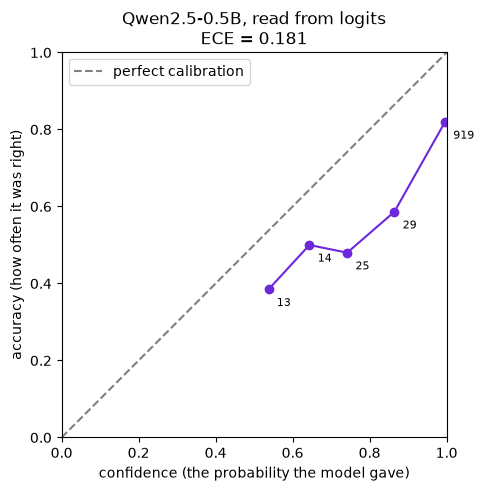

In [17]:
def bin_table(conf, correct, n_bins=10):
    conf, correct = np.asarray(conf), np.asarray(correct, dtype=float)
    edges = np.linspace(0, 1, n_bins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        rows.append({"lo": round(float(lo), 2), "hi": round(float(hi), 2), "n": int(m.sum()),
                     "conf": round(float(conf[m].mean()), 4) if m.any() else None,
                     "acc": round(float(correct[m].mean()), 4) if m.any() else None})
    return rows

def reliability(conf, correct, title, ax):
    rows = [r for r in bin_table(conf, correct) if r["n"]]
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect calibration")
    ax.plot([r["conf"] for r in rows], [r["acc"] for r in rows], "o-", color="#6d28d9")
    for r in rows:
        ax.annotate(str(r["n"]), (r["conf"], r["acc"]), textcoords="offset points", xytext=(6, -12), fontsize=8)
    ax.set(xlabel="confidence (the probability the model gave)", ylabel="accuracy (how often it was right)",
           title=f"{title}\nECE = {ece(conf, correct):.3f}", xlim=(0, 1), ylim=(0, 1), aspect="equal")
    ax.legend(loc="upper left")

probs = test_logits.softmax(-1)
conf, pred = probs.max(-1)
correct = (pred == test_y).float()
print(f"accuracy        {correct.mean():.3f}")
print(f"mean confidence {conf.mean():.3f}   <- the model thinks it is right this often")
print(f"ECE             {ece(conf, correct):.3f}")
fig, ax = plt.subplots(figsize=(5, 5)); reliability(conf, correct, "Qwen2.5-0.5B, read from logits", ax); plt.show()

A few single predictions, so the summary numbers above have faces. `confidence` is the largest of the four probabilities.

In [18]:
wrong = [i for i in range(len(test)) if not correct[i]][:2]
right = [i for i in range(len(test)) if correct[i]][:4]
examples = []
for i in sorted(right + wrong):
    examples.append({"text": test["text"][i][:120], "label": TOPICS[int(test_y[i])], "pred": TOPICS[int(pred[i])],
                     "logits": [round(v, 3) for v in test_logits[i].tolist()], "probs": [round(v, 4) for v in probs[i].tolist()]})
    e = examples[-1]
    print(f"{conf[i]:.3f}  said {e['pred']:<22} truth {e['label']:<22} {e['text'][:60]!r}")

0.999  said Science and technology truth Science and technology 'Spam on the menu at annual virus conference BOSTON - Compute'
1.000  said Business               truth Science and technology 'Microsoft finalises three-year government deal Hot on the he'
0.999  said Science and technology truth Science and technology 'Personal Tech Fast Forward columnist Rob Pegoraro discusses '
0.978  said Science and technology truth Science and technology 'Cassini flies past Titan; pictures expected tonight NASA #39'
0.999  said World                  truth World                  'GOP to Sue Over 573 Found Wash. Ballots (AP) AP - Republican'
1.000  said Business               truth Science and technology 'Toys Will Be Toys Trust me, you don #39;t want to see desper'


## 7. One number fixes most of it: temperature scaling

Divide every logit by a temperature **T** before the softmax. T > 1 flattens the distribution (less sure), T < 1 sharpens it.
The ranking of the options never changes, so accuracy stays the same. We pick the T that gives the best log-likelihood on the 500 tuning items.

In [19]:
z = torch.tensor([2.0, 1.0, 0.1])
for T in [0.5, 1.0, 2.0, 5.0]:
    print(f"T = {T}:  softmax(z / T) =", [round(v, 2) for v in (z / T).softmax(-1).tolist()])

T = 0.5:  softmax(z / T) = [0.86, 0.12, 0.02]
T = 1.0:  softmax(z / T) = [0.66, 0.24, 0.1]
T = 2.0:  softmax(z / T) = [0.5, 0.3, 0.19]
T = 5.0:  softmax(z / T) = [0.4, 0.33, 0.27]


best temperature T = 3.30
accuracy        0.794   (unchanged)
mean confidence 0.801
ECE             0.181  ->  0.032


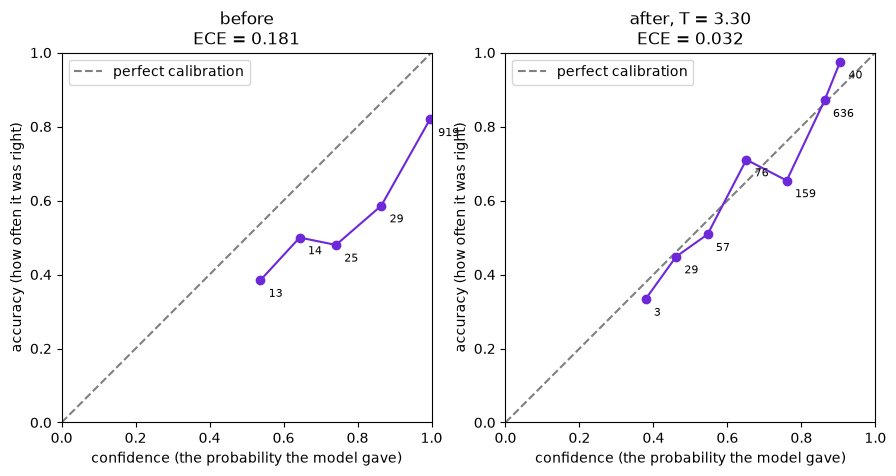

In [20]:
Ts = np.linspace(0.5, 10, 191)
nll = [torch.nn.functional.cross_entropy(val_logits / T, val_y).item() for T in Ts]
T = float(Ts[int(np.argmin(nll))])
print(f"best temperature T = {T:.2f}")

probs_T = (test_logits / T).softmax(-1)
conf_T, pred_T = probs_T.max(-1)
print(f"accuracy        {(pred_T == test_y).float().mean():.3f}   (unchanged)")
print(f"mean confidence {conf_T.mean():.3f}")
print(f"ECE             {ece(conf, correct):.3f}  ->  {ece(conf_T, correct):.3f}")
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5))
reliability(conf, correct, "before", axes[0]); reliability(conf_T, correct, f"after, T = {T:.2f}", axes[1]); plt.show()

## 8. From probabilities to software: thresholds

Act automatically only when the model is sure enough; send the rest to a person (or to a bigger model).
With calibrated probabilities the threshold tells you, in advance, roughly how often the automatic path is wrong.

In [21]:
thresholds = []
print("threshold | handled automatically | wrong among those")
for tau in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    auto = conf_T >= tau
    row = {"tau": tau, "coverage": round(auto.float().mean().item(), 4),
           "error": round(1 - correct[auto].mean().item(), 4), "n": int(auto.sum())}
    thresholds.append(row)
    print(f"   {tau:.1f}    |        {100 * row['coverage']:5.1f}%         |      {100 * row['error']:4.1f}%")

threshold | handled automatically | wrong among those
   0.0    |        100.0%         |      20.6%
   0.5    |         96.8%         |      19.4%
   0.6    |         91.1%         |      17.6%
   0.7    |         83.5%         |      16.5%
   0.8    |         67.6%         |      12.3%
   0.9    |          4.0%         |       2.5%


In [22]:
results = {
    "model": name, "params_M": round(sum(p.numel() for p in model.parameters()) / 1e6), "device": device,
    "layers": model.config.num_hidden_layers, "hidden": model.config.hidden_size, "vocab": model.config.vocab_size,
    "email": email, "tokens": tokens, "token_ids": tok(email)["input_ids"], "prompt_tokens": int(x["input_ids"].shape[1]),
    "next_tokens": next_tokens,
    "letter_logits": [round(v, 3) for v in model(**x).logits[0, -1].float().cpu()[letter_ids[:3]].tolist()],
    "p_team": [round(v, 4) for v in p_team.tolist()], "p_refund_yes": round(p_refund[0].item(), 4),
    "p_urgency": [round(v, 4) for v in p_urgency.tolist()], "urgency_score": round(score, 3),
    "generated": generated, "n_generated": int(n_generated), "passes": int(passes),
    "ms_generate": round(ms_generate), "ms_one_pass": round(ms_one_pass),
    "written": {"n": len(written), "kinds": kinds.most_common(), "examples": {k: v[:200] for k, v in kind_examples.items()},
                "usable": len(stated), "accuracy": round(float(np.mean(stated_right)), 4),
                "mean_stated": round(float(np.mean(stated)), 4), "stated_counts": sorted(Counter(stated).items())},
    "votes": votes.most_common(), "multi": multi,
    "count": {"options": [int(c) for c in counts], "p": [round(v, 4) for v in p_count.tolist()],
              "median": at(0.5), "interval": [at(0.1), at(0.9)]},
    "agnews": {"n": len(test), "accuracy": round(correct.mean().item(), 4),
               "mean_conf": round(conf.mean().item(), 4), "ece": round(ece(conf, correct), 4),
               "bins": bin_table(conf, correct), "T": round(T, 2),
               "mean_conf_T": round(conf_T.mean().item(), 4), "ece_T": round(ece(conf_T, correct), 4),
               "bins_T": bin_table(conf_T, correct), "thresholds": thresholds,
               "conf": [round(v, 3) for v in conf.tolist()], "conf_T": [round(v, 3) for v in conf_T.tolist()],
               "correct": [int(v) for v in correct.tolist()],
               "examples": examples, "nll_curve": [[round(float(t), 2), round(float(v), 4)] for t, v in zip(Ts, nll)][::5],
               "nll_at_1": round(float(nll[int(np.argmin(abs(Ts - 1.0)))]), 4), "nll_best": round(float(min(nll)), 4)},
}
json.dump(results, open("results_1.json", "w"))
print("saved results_1.json")

saved results_1.json


## Things to try

- Change the email. When does the team readout become a coin flip?
- Swap the order of the options. Do the probabilities move? (They do. This is a known weakness of letter readout.)
- Use 15 bins instead of 10 in `ece`. How much does the number change?